In [ ]:
# Min/max and error bars suggested by Claude (Anthropic). Main prompt: "Step 3 of the brief:
# time and speedup per worker count, median with min/max, node and job ID in the title."
# Adapted and corrected by me. Everything else is adapted from Turilli's scaling.ipynb.
# Time and efficiency plots and the title/subtitle idea from Claude (Anthropic); merged into chart() by me.

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

In [53]:
def results(path):
    # One row per number of workers: median times, speedup and efficiency.
    runs = pd.read_csv(path)
    table = runs.groupby("workers")[["pool_start_s", "compute_wall_s", "total_s"]].median()
    table["speedup"] = table["total_s"].iloc[0] / table["total_s"]
    table["efficiency"] = table["speedup"] / table.index
    groups = runs.groupby("workers")["total_s"]
    table["total_min"] = groups.min()
    table["total_max"] = groups.max()
    table["speedup_min"] = table["total_s"].iloc[0] / table["total_max"]
    table["speedup_max"] = table["total_s"].iloc[0] / table["total_min"]
    return table.round(3)

def amdahl(s, n):
    return 1 / (s + (1 - s) / n)

def chart(table, color, plot):
    s = table["pool_start_s"].iloc[0] / table["total_s"].iloc[0]
    n = table.index
    if plot == 0:
        plt.plot(n, table["total_s"].iloc[0] / n, "--", color="#898781", label="ideal")
        errorbar = [table["total_s"] - table["total_min"], table["total_max"] - table["total_s"]]
        plt.ylabel("total time")
        plt.errorbar(n, table["total_s"], yerr=errorbar, capsize=3, fmt="o-", color=color, label=f"measured")
        plt.suptitle("Time plot")
    elif plot == 1:
        plt.plot(n, n, "--", color="#898781", label="ideal")
        plt.plot(n, amdahl(s, n), color="#c3c2b7", linewidth=3, label=f"Amdahl, s = {s:.1%}")
        errorbar = [table["speedup"] - table["speedup_min"], table["speedup_max"] - table["speedup"]]
        plt.ylabel("speedup")
        plt.errorbar(n, table["speedup"], yerr=errorbar, capsize=3, fmt="o-", color=color, label=f"measured")
        plt.suptitle("Speedup plot")
    else:
        plt.plot(n, compute["efficiency"], "o-", color= color, label = "Efficiency")
        plt.axhline(1, ls="--", color="#898781", label="ideal")
        plt.ylabel("efficiency")
        plt.suptitle("Efficiency plot")
    plt.xscale("log", base=2)
    plt.xticks(n, n)
    plt.xlabel("workers")
    plt.title(f"node {runs['node'].iloc[0]} & job {runs['job_id'].iloc[0]}")
    plt.legend()

def serial_fraction(table):
    n = table.index[1:]
    S = table["speedup"].iloc[1:]
    return ((1 / S - 1 / n) / (1 - 1 / n)).round(3)


In [54]:
compute = results("..\\results\\scaling-30212.csv")
compute

serial_fraction(compute)

workers
2     0.012
4     0.009
8     0.006
16    0.006
dtype: float64

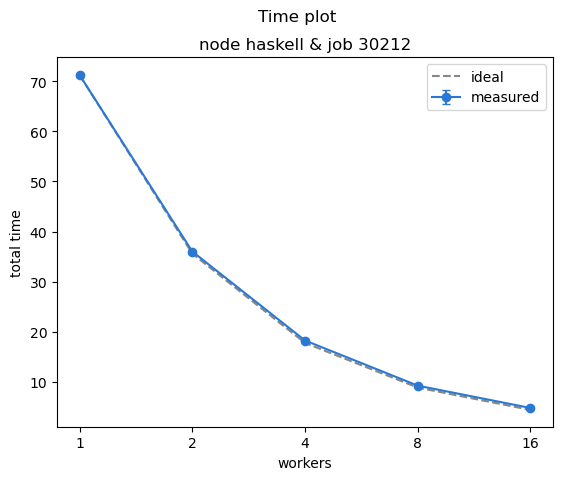

In [55]:
chart(compute, "#2a78d6", 0)

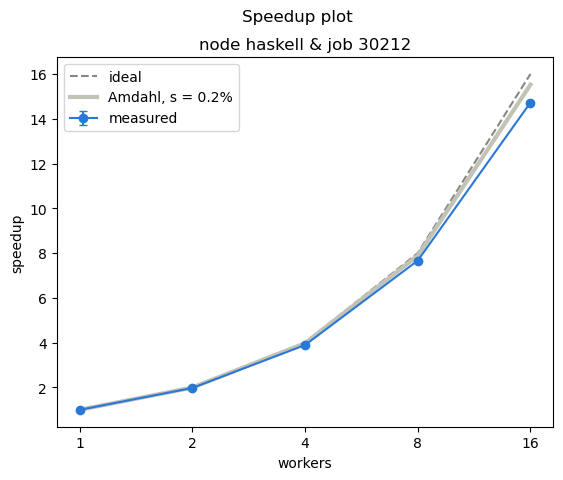

In [56]:
chart(compute, "#2a78d6", 1)

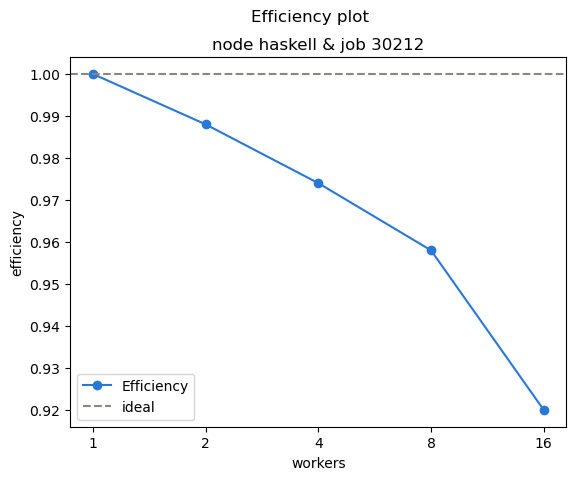

In [57]:
chart(compute, "#2a78d6", 2)